In [1]:
from pathlib import Path
import pandas as pd

# Check the current working directory
print("Working directory:", Path.cwd())

# Find the data folder
if Path("notebook/data").exists():
    DATA_DIR = Path("notebook/data")
elif Path("data").exists():
    DATA_DIR = Path("data")
else:
    raise FileNotFoundError(
        "Data folder not found. Check your folder structure."
    )

print("\nData folder:", DATA_DIR.resolve())

# Display the files available in the folder
print("\nFiles found:")
for file in DATA_DIR.iterdir():
    if file.is_file():
        print(file.name)

Working directory: d:\AI ML project\airline-satisfaction-prediction\notebook

Data folder: D:\AI ML project\airline-satisfaction-prediction\notebook\data

Files found:
sample_submission.csv
test.csv
train.csv


In [2]:
# Load the three CSV files
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission_df = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Display dataset shapes
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)
print("Sample submission shape:", sample_submission_df.shape)

Training data shape: (699635, 23)
Test data shape: (299844, 22)
Sample submission shape: (299844, 2)


In [3]:
# Display all column names
print("TRAINING COLUMNS:")
print(train_df.columns.tolist())

print("\nTEST COLUMNS:")
print(test_df.columns.tolist())

print("\nSAMPLE SUBMISSION COLUMNS:")
print(sample_submission_df.columns.tolist())

TRAINING COLUMNS:
['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

TEST COLUMNS:
['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']

SAMPLE SUBMISSION COLUMNS:
['id', 'satisfaction']


## Check data types and missing values

In [4]:
# Display data types of every training column
print("DATA TYPES:")
train_df.info()

# Count missing values in each column
print("\nMISSING VALUES:")
print(train_df.isnull().sum())

# Calculate the percentage of missing values
print("\nMISSING VALUE PERCENTAGE:")
missing_percentage = (
    train_df.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percentage[missing_percentage > 0])

DATA TYPES:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service           

## Check the target distribution

In [5]:
# Count each satisfaction class
print("SATISFACTION COUNTS:")
print(train_df["satisfaction"].value_counts())

# Calculate class percentages
print("\nSATISFACTION PERCENTAGES:")
print(
    (train_df["satisfaction"].value_counts(normalize=True) * 100)
    .round(2)
)

# Check the unique target values
print("\nUNIQUE TARGET VALUES:")
print(train_df["satisfaction"].unique())

SATISFACTION COUNTS:
satisfaction
False    389296
True     310339
Name: count, dtype: int64

SATISFACTION PERCENTAGES:
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64

UNIQUE TARGET VALUES:
[False  True]


## Inspect numerical statistics

In [6]:
# Display summary statistics for numerical columns
print("NUMERICAL FEATURE STATISTICS:")
display(train_df.describe().T)

NUMERICAL FEATURE STATISTICS:


,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372129,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


## Check categorical features

In [7]:
# Select categorical columns
categorical_columns = train_df.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

# Display the unique values and their counts
for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(train_df[column].value_counts(dropna=False))

Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

--- Gender ---
Gender
Male      351683
Female    347952
Name: count, dtype: int64

--- Customer Type ---
Customer Type
Loyal Customer       576990
disloyal Customer    122645
Name: count, dtype: int64

--- Type of Travel ---
Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64

--- Class ---
Class
Business    342212
Eco         327404
Eco Plus     30019
Name: count, dtype: int64

--- satisfaction ---
satisfaction
False    389296
True     310339
Name: count, dtype: int64


## Compare training and test data

In [8]:
# Identify the target column
target_column = "satisfaction"

# Get training features without the target
train_features = train_df.drop(columns=[target_column])

# Compare feature columns
print("Same feature columns:", 
      set(train_features.columns) == set(test_df.columns))

print("\nColumns in training but not test:")
print(set(train_features.columns) - set(test_df.columns))

print("\nColumns in test but not training:")
print(set(test_df.columns) - set(train_features.columns))

# Check duplicate rows
print("\nDuplicate rows in training:", train_df.duplicated().sum())
print("Duplicate IDs in training:", train_df["id"].duplicated().sum())
print("Duplicate IDs in test:", test_df["id"].duplicated().sum())

Same feature columns: True

Columns in training but not test:
set()

Columns in test but not training:
set()

Duplicate rows in training: 0
Duplicate IDs in training: 0
Duplicate IDs in test: 0


## Start visual EDA

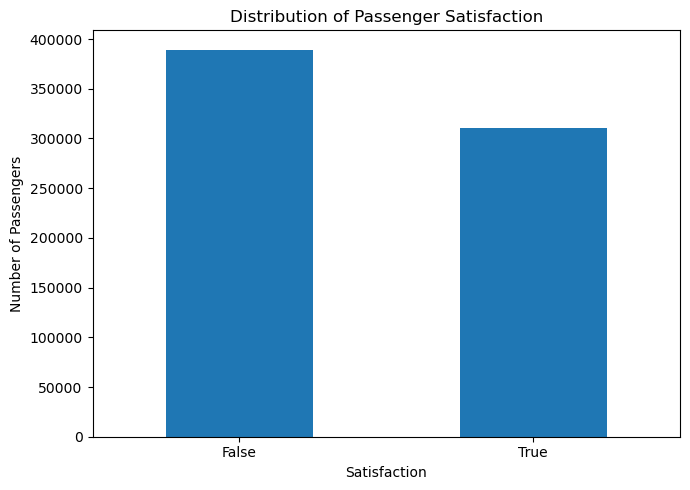

In [9]:
import matplotlib.pyplot as plt

# Count satisfied and unsatisfied passengers
satisfaction_counts = train_df["satisfaction"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 5))
satisfaction_counts.plot(kind="bar")

plt.title("Distribution of Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Compare satisfaction by travel type

Satisfaction percentage by travel type:


satisfaction,False,True
Type of Travel,,
Business travel,41.57,58.43
Personal Travel,90.27,9.73


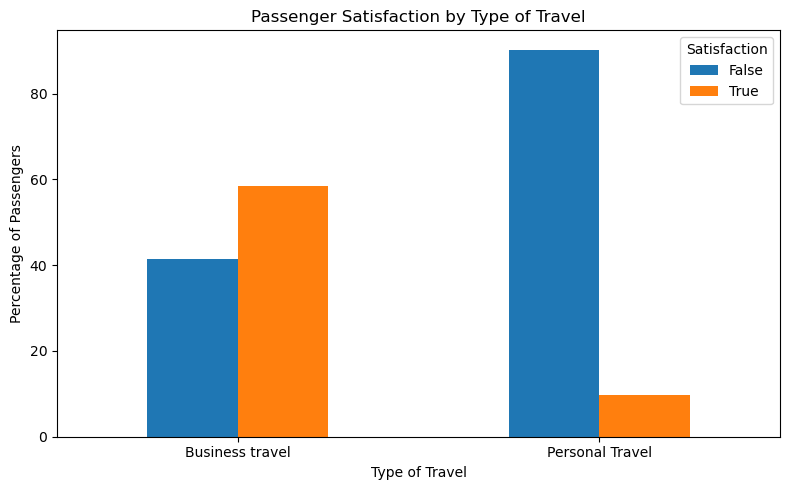

In [10]:
# Create a cross-tabulation of travel type and satisfaction
travel_satisfaction = pd.crosstab(
    train_df["Type of Travel"],
    train_df["satisfaction"],
    normalize="index"
) * 100

print("Satisfaction percentage by travel type:")
display(travel_satisfaction.round(2))

# Plot the percentages
travel_satisfaction.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Passenger Satisfaction by Type of Travel")
plt.xlabel("Type of Travel")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

## Compare satisfaction by passenger class

Satisfaction percentage by passenger class:


satisfaction,False,True
Class,,
Business,27.47,72.53
Eco,83.24,16.76
Eco Plus,75.78,24.22


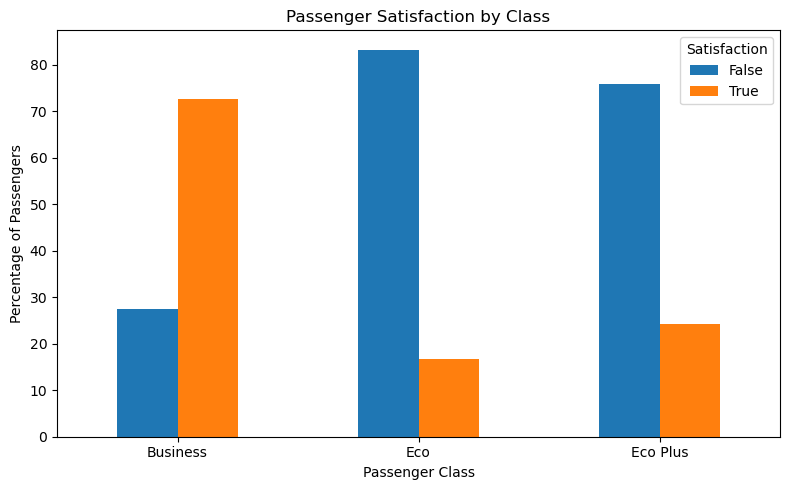

In [11]:
# Calculate satisfaction percentages for each passenger class
class_satisfaction = pd.crosstab(
    train_df["Class"],
    train_df["satisfaction"],
    normalize="index"
) * 100

print("Satisfaction percentage by passenger class:")
display(class_satisfaction.round(2))

# Visualize the results
class_satisfaction.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Passenger Satisfaction by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

## Investigate service ratings

In [12]:
# Select service rating features
rating_columns = [
    "Online boarding",
    "Inflight wifi service",
    "Seat comfort"
]

# Calculate satisfaction percentages for each rating
for column in rating_columns:
    rating_satisfaction = pd.crosstab(
        train_df[column],
        train_df["satisfaction"],
        normalize="index"
    ) * 100

    print(f"\nSatisfaction percentage by {column}:")
    display(rating_satisfaction.round(2))


Satisfaction percentage by Online boarding:


satisfaction,False,True
Online boarding,,
0,37.96,62.04
1,89.47,10.53
2,91.46,8.54
3,87.16,12.84
4,35.81,64.19
5,12.49,87.51



Satisfaction percentage by Inflight wifi service:


satisfaction,False,True
Inflight wifi service,,
0,11.27,88.73
1,60.93,39.07
2,72.96,27.04
3,72.38,27.62
4,37.78,62.22
5,4.96,95.04



Satisfaction percentage by Seat comfort:


satisfaction,False,True
Seat comfort,,
0,81.62,18.38
1,82.64,17.36
2,82.80,17.20
3,81.51,18.49
4,42.94,57.06
5,32.89,67.11


## Check rating counts and missing values in the test set

In [13]:
# Check the number of passengers at each rating
rating_columns = [
    "Online boarding",
    "Inflight wifi service",
    "Seat comfort"
]

for column in rating_columns:
    print(f"\nPassenger counts: {column}")
    print(train_df[column].value_counts().sort_index())

# Check missing values in training and test
print("\nMissing values in training:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("\nMissing values in test:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])


Passenger counts: Online boarding
Online boarding
0      9147
1     57588
2    119297
3    149783
4    210950
5    152870
Name: count, dtype: int64

Passenger counts: Inflight wifi service
Inflight wifi service
0     13102
1    107739
2    186870
3    184436
4    128136
5     79352
Name: count, dtype: int64

Passenger counts: Seat comfort
Seat comfort
0       838
1     63130
2     92471
3    120182
4    226726
5    196288
Name: count, dtype: int64

Missing values in training:
Arrival Delay in Minutes    292
dtype: int64

Missing values in test:
Arrival Delay in Minutes    130
dtype: int64


## Check the Kaggle submission format

In [14]:
# Inspect the sample submission
print("Sample submission preview:")
display(sample_submission_df.head())

print("\nSample submission data types:")
print(sample_submission_df.dtypes)

print("\nTraining target data type:")
print(train_df["satisfaction"].dtype)

print("\nTest IDs match sample submission IDs:",
      test_df["id"].equals(sample_submission_df["id"]))

Sample submission preview:


,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573



Sample submission data types:
id                int64
satisfaction    float64
dtype: object

Training target data type:
bool

Test IDs match sample submission IDs: True


## Phase 1 complete — prepare model validation

In [15]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = train_df.drop(columns=["satisfaction", "id"])
y = train_df["satisfaction"]

# Split data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the results
print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_valid.value_counts(normalize=True).round(4))

Training features: (559708, 21)
Validation features: (139927, 21)

Training target distribution:
satisfaction
False    0.5564
True     0.4436
Name: proportion, dtype: float64

Validation target distribution:
satisfaction
False    0.5564
True     0.4436
Name: proportion, dtype: float64


## Build our first baseline model

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

# Preprocess numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# Create the complete model pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Predict probabilities on validation data
y_valid_proba = baseline_model.predict_proba(X_valid)[:, 1]

# Calculate ROC-AUC
baseline_auc = roc_auc_score(y_valid, y_valid_proba)

print("\nBaseline Logistic Regression ROC-AUC:", round(baseline_auc, 5))

Numerical columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Baseline Logistic Regression ROC-AUC: 0.92046


## Compare with a stronger model

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Transform data using the fitted baseline preprocessor
X_train_processed = baseline_model.named_steps[
    "preprocessor"
].transform(X_train)

X_valid_processed = baseline_model.named_steps[
    "preprocessor"
].transform(X_valid)

print("Training matrix shape:", X_train_processed.shape)
print("Validation matrix shape:", X_valid_processed.shape)

# Create a Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict satisfaction probabilities
rf_valid_proba = rf_model.predict_proba(X_valid_processed)[:, 1]

# Evaluate ROC-AUC
rf_auc = roc_auc_score(y_valid, rf_valid_proba)

print("\nLogistic Regression ROC-AUC:", round(baseline_auc, 5))
print("Random Forest ROC-AUC:", round(rf_auc, 5))

Training matrix shape: (559708, 26)
Validation matrix shape: (139927, 26)

Logistic Regression ROC-AUC: 0.92046
Random Forest ROC-AUC: 0.95461


In [18]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1


In [19]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

xgb_valid_proba = xgb_model.predict_proba(X_valid_processed)[:, 1]

xgb_auc = roc_auc_score(y_valid, xgb_valid_proba)

print("Logistic Regression ROC-AUC:", round(baseline_auc, 5))
print("Random Forest ROC-AUC:", round(rf_auc, 5))
print("XGBoost ROC-AUC:", round(xgb_auc, 5))

Logistic Regression ROC-AUC: 0.92046
Random Forest ROC-AUC: 0.95461
XGBoost ROC-AUC: 0.95707


## Next step: Tune XGBoost

In [20]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

param_grid = {
    "max_depth": [4, 6],
    "learning_rate": [0.03, 0.05],
    "min_child_weight": [1, 5]
}

tuning_results = []

for params in ParameterGrid(param_grid):
    model = XGBClassifier(
        n_estimators=300,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(X_train_processed, y_train)

    probabilities = model.predict_proba(X_valid_processed)[:, 1]
    auc = roc_auc_score(y_valid, probabilities)

    tuning_results.append({
        **params,
        "roc_auc": auc
    })

    print(params, "ROC-AUC:", round(auc, 5))

results_df = pd.DataFrame(tuning_results)
results_df = results_df.sort_values("roc_auc", ascending=False)

print("\nBest configuration:")
print(results_df.iloc[0])

{'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 1} ROC-AUC: 0.95375
{'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5} ROC-AUC: 0.95381
{'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 1} ROC-AUC: 0.95624
{'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5} ROC-AUC: 0.95622
{'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 1} ROC-AUC: 0.95529
{'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5} ROC-AUC: 0.9553
{'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1} ROC-AUC: 0.95707
{'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 5} ROC-AUC: 0.95713

Best configuration:
learning_rate       0.050000
max_depth           6.000000
min_child_weight    5.000000
roc_auc             0.957134
Name: 7, dtype: float64


## Next step: Create your first Kaggle submission

In [21]:
from xgboost import XGBClassifier
from pathlib import Path
import pandas as pd

# Prepare all training features
X_full = train_df.drop(columns=["satisfaction", "id"])
y_full = train_df["satisfaction"].astype(int)

# Prepare test features
X_test = test_df.drop(columns=["id"])

# Reuse the preprocessing pipeline
final_preprocessor = baseline_model.named_steps["preprocessor"]

X_full_processed = final_preprocessor.fit_transform(X_full)
X_test_processed = final_preprocessor.transform(X_test)

# Train the tuned XGBoost model
final_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_full_processed, y_full)

# Predict probabilities for Kaggle
test_probabilities = final_model.predict_proba(
    X_test_processed
)[:, 1]

# Create submission file
submission = pd.DataFrame({
    "id": test_df["id"],
    "satisfaction": test_probabilities
})

output_path = Path("submission.csv")
submission.to_csv(output_path, index=False)

print("Submission shape:", submission.shape)
print("\nSubmission preview:")
print(submission.head())

print("\nMissing predictions:", submission["satisfaction"].isna().sum())
print("Minimum probability:", submission["satisfaction"].min())
print("Maximum probability:", submission["satisfaction"].max())
print("Saved to:", output_path.resolve())

Submission shape: (299844, 2)

Submission preview:
       id  satisfaction
0  699635      0.241610
1  699636      0.873443
2  699637      0.901361
3  699638      0.055901
4  699639      0.071638

Missing predictions: 0
Minimum probability: 0.004934776574373245
Maximum probability: 0.9945045113563538
Saved to: D:\AI ML project\airline-satisfaction-prediction\notebook\submission.csv


## Check CatBoost

In [22]:
try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except ImportError:
    print("CatBoost is not installed.")

CatBoost version: 1.2.10


In [23]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

cat_model = CatBoostClassifier(
    iterations=1000,
    depth=8,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model.fit(
    X_train,
    y_train.astype(int),
    cat_features=["Gender", "Customer Type", "Type of Travel", "Class"],
    eval_set=(X_valid, y_valid.astype(int)),
    early_stopping_rounds=100,
    verbose=100
)

cat_valid_prob = cat_model.predict_proba(X_valid)[:, 1]
cat_auc = roc_auc_score(y_valid, cat_valid_prob)

print("CatBoost Validation ROC-AUC:", round(cat_auc, 5))
print("Previous XGBoost Validation ROC-AUC: 0.95713")

0:	test: 0.9438315	best: 0.9438315 (0)	total: 567ms	remaining: 9m 26s
100:	test: 0.9550846	best: 0.9550846 (100)	total: 30.9s	remaining: 4m 34s
200:	test: 0.9564448	best: 0.9564448 (200)	total: 1m	remaining: 4m 2s
300:	test: 0.9569096	best: 0.9569096 (300)	total: 1m 32s	remaining: 3m 35s
400:	test: 0.9571918	best: 0.9571944 (399)	total: 2m 2s	remaining: 3m 3s
500:	test: 0.9573460	best: 0.9573460 (500)	total: 2m 35s	remaining: 2m 34s
600:	test: 0.9574423	best: 0.9574423 (600)	total: 3m 6s	remaining: 2m 4s
700:	test: 0.9575196	best: 0.9575276 (695)	total: 3m 38s	remaining: 1m 33s
800:	test: 0.9576059	best: 0.9576059 (800)	total: 4m 11s	remaining: 1m 2s
900:	test: 0.9576413	best: 0.9576479 (874)	total: 4m 44s	remaining: 31.2s
999:	test: 0.9577196	best: 0.9577196 (999)	total: 5m 16s	remaining: 0us

bestTest = 0.9577196261
bestIteration = 999

CatBoost Validation ROC-AUC: 0.95772
Previous XGBoost Validation ROC-AUC: 0.95713


In [24]:
from catboost import CatBoostClassifier
import pandas as pd

X_full = train_df.drop(columns=["satisfaction", "id"])
y_full = train_df["satisfaction"].astype(int)
X_test = test_df.drop(columns=["id"])

final_cat_model = CatBoostClassifier(
    iterations=1000,
    depth=8,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_cat_model.fit(
    X_full,
    y_full,
    cat_features=["Gender", "Customer Type", "Type of Travel", "Class"]
)

test_probabilities = final_cat_model.predict_proba(X_test)[:, 1]

cat_submission = pd.DataFrame({
    "id": test_df["id"],
    "satisfaction": test_probabilities
})

cat_submission.to_csv("catboost_submission.csv", index=False)

print(cat_submission.head())
print("Shape:", cat_submission.shape)
print("Missing predictions:", cat_submission["satisfaction"].isna().sum())
print("Saved: catboost_submission.csv")

0:	learn: 0.6394384	total: 357ms	remaining: 5m 56s
100:	learn: 0.2356538	total: 39.5s	remaining: 5m 51s
200:	learn: 0.2290462	total: 1m 17s	remaining: 5m 8s
300:	learn: 0.2264259	total: 1m 54s	remaining: 4m 25s
400:	learn: 0.2247855	total: 2m 29s	remaining: 3m 43s
500:	learn: 0.2234112	total: 3m 5s	remaining: 3m 4s
600:	learn: 0.2222113	total: 3m 42s	remaining: 2m 27s
700:	learn: 0.2211193	total: 4m 18s	remaining: 1m 50s
800:	learn: 0.2202203	total: 4m 53s	remaining: 1m 12s
900:	learn: 0.2193091	total: 5m 29s	remaining: 36.2s
999:	learn: 0.2184152	total: 6m 5s	remaining: 0us
       id  satisfaction
0  699635      0.261999
1  699636      0.894288
2  699637      0.904452
3  699638      0.068605
4  699639      0.069249
Shape: (299844, 2)
Missing predictions: 0
Saved: catboost_submission.csv


Generate XGBoost predictions

In [25]:
from xgboost import XGBClassifier
import pandas as pd

# Prepare the full training and test datasets
X_full = train_df.drop(columns=["satisfaction", "id"])
y_full = train_df["satisfaction"].astype(int)
X_test = test_df.drop(columns=["id"])

# Fit preprocessing on the full training data
xgb_preprocessor = baseline_model.named_steps["preprocessor"]

X_full_processed = xgb_preprocessor.fit_transform(X_full)
X_test_processed = xgb_preprocessor.transform(X_test)

# Train XGBoost using your best parameters
final_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(X_full_processed, y_full)

# Generate test probabilities
xgb_test_prob = final_xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Save predictions separately
pd.DataFrame({
    "id": test_df["id"],
    "satisfaction": xgb_test_prob
}).to_csv("xgboost_full_predictions.csv", index=False)

print("XGBoost predictions saved successfully.")
print("Number of predictions:", len(xgb_test_prob))

XGBoost predictions saved successfully.
Number of predictions: 299844


Blend XGBoost and CatBoost

In [26]:
import pandas as pd
import numpy as np

# Load predictions from both models
xgb_pred = pd.read_csv("xgboost_full_predictions.csv")
cat_pred = pd.read_csv("catboost_submission.csv")

# Verify IDs match
assert xgb_pred["id"].equals(cat_pred["id"]), "IDs do not match!"

# Blend predictions: 50% XGBoost + 50% CatBoost
blended_prob = (
    0.5 * xgb_pred["satisfaction"]
    + 0.5 * cat_pred["satisfaction"]
)

# Create a new submission file
blend_submission = pd.DataFrame({
    "id": xgb_pred["id"],
    "satisfaction": blended_prob
})

blend_submission.to_csv("blended_submission.csv", index=False)

print("Blended submission saved!")
print("Shape:", blend_submission.shape)
print("Missing predictions:", blend_submission["satisfaction"].isna().sum())
print(blend_submission.head())

Blended submission saved!
Shape: (299844, 2)
Missing predictions: 0
       id  satisfaction
0  699635      0.251804
1  699636      0.883865
2  699637      0.902907
3  699638      0.062253
4  699639      0.070444


In [27]:
try:
    import lightgbm
    print("LightGBM version:", lightgbm.__version__)
except ImportError:
    print("LightGBM is not installed.")

LightGBM is not installed.


In [28]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------

In [29]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.7.0


In [30]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score

lgb_model = LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    X_train,
    y_train.astype(int),
    eval_set=[(X_valid, y_valid.astype(int))],
    eval_metric="auc",
    callbacks=[
        early_stopping(100),
        log_evaluation(100)
    ]
)

lgb_valid_prob = lgb_model.predict_proba(X_valid)[:, 1]
lgb_auc = roc_auc_score(y_valid, lgb_valid_prob)

print("LightGBM Validation ROC-AUC:", round(lgb_auc, 5))
print("CatBoost Validation ROC-AUC: 0.95772")
print("XGBoost Validation ROC-AUC: 0.95713")

c:\Users\rahul\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ValueError: pandas dtypes must be int, float or bool.
Fields with bad pandas dtypes: Gender: object, Customer Type: object, Type of Travel: object, Class: object

In [31]:
import pandas as pd
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score

categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

# Create copies
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

# Convert categorical columns
for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_valid_lgb[col] = X_valid_lgb[col].astype("category")

print(X_train_lgb[categorical_cols].dtypes)

Gender            category
Customer Type     category
Type of Travel    category
Class             category
dtype: object


In [32]:
lgb_model = LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train.astype(int),
    eval_set=[(X_valid_lgb, y_valid.astype(int))],
    eval_metric="auc",
    callbacks=[
        early_stopping(100),
        log_evaluation(100)
    ],
    categorical_feature=categorical_cols
)

lgb_valid_prob = lgb_model.predict_proba(X_valid_lgb)[:, 1]
lgb_auc = roc_auc_score(y_valid, lgb_valid_prob)

print("LightGBM Validation ROC-AUC:", round(lgb_auc, 5))
print("CatBoost Validation ROC-AUC: 0.95772")

c:\Users\rahul\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.953261	valid_0's binary_logloss: 0.24973
[200]	valid_0's auc: 0.955847	valid_0's binary_logloss: 0.235058
[300]	valid_0's auc: 0.95677	valid_0's binary_logloss: 0.232916
[400]	valid_0's auc: 0.957119	valid_0's binary_logloss: 0.23202
[500]	valid_0's auc: 0.957257	valid_0's binary_logloss: 0.231693
[600]	valid_0's auc: 0.957317	valid_0's binary_logloss: 0.231449
[700]	valid_0's auc: 0.957405	valid_0's binary_logloss: 0.231199
[800]	valid_0's auc: 0.957443	valid_0's binary_logloss: 0.231117
[900]	valid_0's auc: 0.957489	valid_0's binary_logloss: 0.231007
[1000]	valid_0's auc: 0.957524	valid_0's binary_logloss: 0.230925
[1100]	valid_0's auc: 0.957555	valid_0's binary_logloss: 0.23085
[1200]	valid_0's auc: 0.957581	valid_0's binary_logloss: 0.230786
[1300]	valid_0's auc: 0.957626	valid_0's binary_logloss: 0.23067
[1400]	valid_0's auc: 0.957654	valid_0's binary_logloss: 0.230627
[1500]	valid_0's auc: 0.9576

In [33]:
import numpy as np
from sklearn.metrics import roc_auc_score

# Get CatBoost validation probabilities
cat_valid_prob = cat_model.predict_proba(X_valid)[:, 1]

# LightGBM validation probabilities
lgb_valid_prob = lgb_model.predict_proba(X_valid_lgb)[:, 1]

# Blend both models
blend_valid_prob = (
    0.5 * cat_valid_prob +
    0.5 * lgb_valid_prob
)

# Evaluate
blend_auc = roc_auc_score(y_valid, blend_valid_prob)

print("CatBoost AUC:", round(roc_auc_score(y_valid, cat_valid_prob), 6))
print("LightGBM AUC:", round(roc_auc_score(y_valid, lgb_valid_prob), 6))
print("Blended AUC:", round(blend_auc, 6))

CatBoost AUC: 0.95772
LightGBM AUC: 0.957672
Blended AUC: 0.957895


In [34]:
# Convert full training and test categorical columns
X_full_lgb = train_df.drop(columns=["satisfaction", "id"]).copy()
X_test_lgb = test_df.drop(columns=["id"]).copy()

categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for col in categorical_cols:
    categories = X_full_lgb[col].astype("category").cat.categories

    X_full_lgb[col] = pd.Categorical(
        X_full_lgb[col], categories=categories
    )
    X_test_lgb[col] = pd.Categorical(
        X_test_lgb[col], categories=categories
    )

# Train LightGBM on all training rows
lgb_final = LGBMClassifier(
    n_estimators=1433,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_final.fit(
    X_full_lgb,
    train_df["satisfaction"].astype(int),
    categorical_feature=categorical_cols
)

print("Full-data LightGBM training completed!")

Full-data LightGBM training completed!


In [35]:
import numpy as np
import pandas as pd

# CatBoost predictions on test data
cat_test_prob = cat_model.predict_proba(
    test_df.drop(columns=["id"])
)[:, 1]

# LightGBM predictions on test data
lgb_test_prob = lgb_final.predict_proba(X_test_lgb)[:, 1]

# Blend the predictions
blended_prob = (
    0.5 * cat_test_prob +
    0.5 * lgb_test_prob
)

# Create Kaggle submission
submission = pd.DataFrame({
    "id": test_df["id"],
    "satisfaction": blended_prob
})

# Save the file
submission.to_csv("catboost_lightgbm_blend.csv", index=False)

# Verify the file
print("Shape:", submission.shape)
print("Missing values:", submission.isnull().sum().sum())
print(submission.head())
print("Saved as catboost_lightgbm_blend.csv")

Shape: (299844, 2)
Missing values: 0
       id  satisfaction
0  699635      0.239222
1  699636      0.903227
2  699637      0.905480
3  699638      0.067727
4  699639      0.053711
Saved as catboost_lightgbm_blend.csv


In [36]:
from pathlib import Path

project_path = Path(r"D:\AI ML project\airline-satisfaction-prediction")

print("PROJECT FOLDER")
print(project_path)

print("\nFILES AND FOLDERS")
for item in sorted(project_path.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)

print("\nNOTEBOOK FOLDER")
notebook_path = project_path / "notebook"

if notebook_path.exists():
    for item in sorted(notebook_path.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)

PROJECT FOLDER
D:\AI ML project\airline-satisfaction-prediction

FILES AND FOLDERS
📄 .gitignore
📁 notebook

NOTEBOOK FOLDER
📄 01_inspect.ipynb
📄 airline_satisfaction_blend.csv
📄 catboost_lightgbm_blend.csv
📄 catboost_submission.csv
📁 data
📄 submission.csv
📄 xgboost_full_predictions.csv
